# Análisis de precios de supermercados (CABA y GBA)

Responde las cinco preguntas del proyecto con el modelo de la etapa 4 (`data/modelo.duckdb`). Las consultas están en `sql/05_analisis/`; este notebook las corre y las grafica.

> **Lectura con 7 días de datos (12 al 18 de noviembre de 2026).** Las comparaciones entre cadenas ya se pueden leer; la evolución en el tiempo todavía no.
> Las conclusiones de cada sección están escritas con esos datos. Para actualizarlas: `python -m src.modelo` y volver a correr el notebook.

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
con = duckdb.connect(str(RAIZ / "data" / "modelo.duckdb"), read_only=True)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COLOR, RESALTADO = "#4C78A8", "#E45756"


def consulta(nombre):
    """Corre una consulta de sql/05_analisis/ y devuelve un DataFrame."""
    return con.sql((RAIZ / "sql" / "05_analisis" / nombre).read_text(encoding="utf-8")).df()


dias = con.sql("select min(fecha), max(fecha), count(distinct fecha) from fct_precio_representativo").fetchall()[0]
print(f"Datos del {dias[0]} al {dias[1]} ({dias[2]} días)")

Datos del 2026-11-12 al 2026-11-18 (7 días)


## 1. ¿Cuánto cambia el precio del mismo producto según la cadena y la zona?

**Entre cadenas.** Para cada producto de la canasta: cuánto más cuesta en la cadena más cara que en la más barata (mediana de los días, 10 cadenas comparables).

,categoria,producto,rango_pct,precio_min,precio_max,n_cadenas,dias
0,Limpieza,Detergente Magistral limón 500 ml,47.3,3739.0,5507.0,10,7
1,Almacén,Fideos spaghetti Lucchetti N7 500 g,44.6,1349.0,1950.0,10,7
2,Almacén,Arroz parboil Gallo Oro 500 g,44.0,1215.0,1750.0,10,7
3,Higiene,Shampoo Sedal crema balance 340 ml,40.3,4989.0,7000.0,10,7
4,Almacén,Sal fina Celusal 500 g,37.3,1529.0,2100.0,10,7
5,Almacén,Café molido La Virginia 250 g,33.6,5989.0,8000.0,10,7
6,Almacén,Yerba mate Amanda 500 g,32.6,2149.0,2850.0,10,7
7,Higiene,Desodorante antitranspirante Rexona 60 g,32.0,2469.0,3259.0,10,7
8,Almacén,Caldo Knorr sabor gallina 12 cubos,29.3,2549.0,3295.0,10,7
9,Higiene,Jabón de tocador Dove 90 g,28.8,2330.0,3000.0,10,7


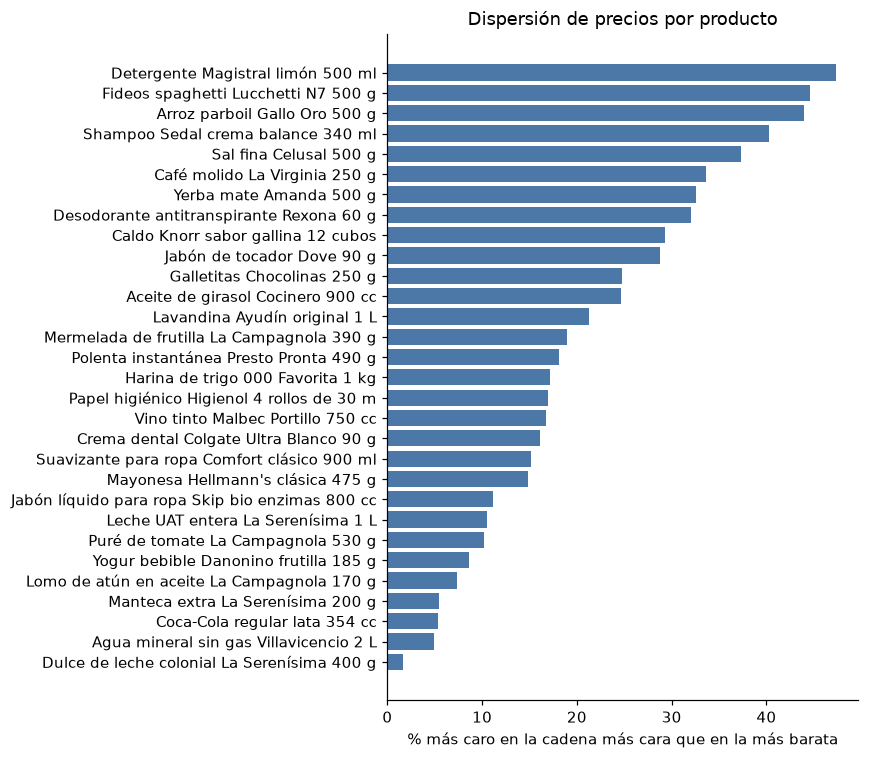

In [2]:
disp = consulta("03_dispersion_por_producto.sql")
fig, ax = plt.subplots(figsize=(8, 7))
d = disp.sort_values("rango_pct")
ax.barh(d["producto"], d["rango_pct"], color=COLOR)
ax.set_xlabel("% más caro en la cadena más cara que en la más barata")
ax.set_title("Dispersión de precios por producto")
plt.tight_layout()
disp.head(10)

**Entre zonas.** Mismo método, pero comparando la misma cadena en CABA y en GBA.

In [3]:
zonas = consulta("02_misma_cadena_entre_zonas.sql")
zonas

,cadena,costo_caba,costo_gba,gba_vs_caba_pct
0,Carrefour Maxi,97232.0,97277.0,0.0
1,Carrefour Market,107364.0,107364.0,0.0
2,Carrefour Hipermercado,108646.0,108646.0,0.0
3,DIA,109095.0,109095.0,0.0
4,Coto,109208.9,109208.9,0.0
5,Vea,110300.0,110300.0,0.0
6,Disco,114474.0,114474.0,0.0
7,Carrefour Express,110313.5,110001.0,-0.3
8,Jumbo,112948.0,112665.0,-0.3


**Qué se ve:**
- La dispersión entre cadenas es grande y desigual: el detergente, los fideos, el arroz y el shampoo cuestan entre 40% y 47% más en la cadena más cara; las gaseosas, el agua y el dulce de leche, menos de 6%.
- **La zona casi no importa:** la misma cadena cobra lo mismo en CABA que en GBA (diferencia de 0% a −0,3%). Las cadenas fijan precios para todo el área, así que la diferencia relevante está en **qué cadena** se elige, no en dónde se vive.
- Como la cadena fija casi un precio único para toda el área, controlar por zona no cambia el ranking; sirve para confirmarlo.

## 2. ¿En qué cadena sale más barata la canasta y cuánto se ahorra?

Costo de 30 productos básicos (una unidad de cada uno), último día disponible, solo cadenas comparables con canasta completa.

,posicion,cadena,costo_canasta,sobre_la_mas_barata_pct,ahorro_vs_mas_cara_pct
19,1,Carrefour Maxi,97277.0,0.00,15.02
20,2,Changomas,106705.0,9.69,6.79
21,3,Carrefour Market,107364.0,10.37,6.21
22,4,Carrefour Hipermercado,108646.0,11.69,5.09
23,5,DIA,109095.0,12.15,4.70
24,6,Coto,109208.9,12.27,4.60
25,7,Carrefour Express,110001.0,13.08,3.91
26,8,Vea,110300.0,13.39,3.65
27,9,Jumbo,112665.0,15.82,1.58
28,10,Disco,114474.0,17.68,0.00


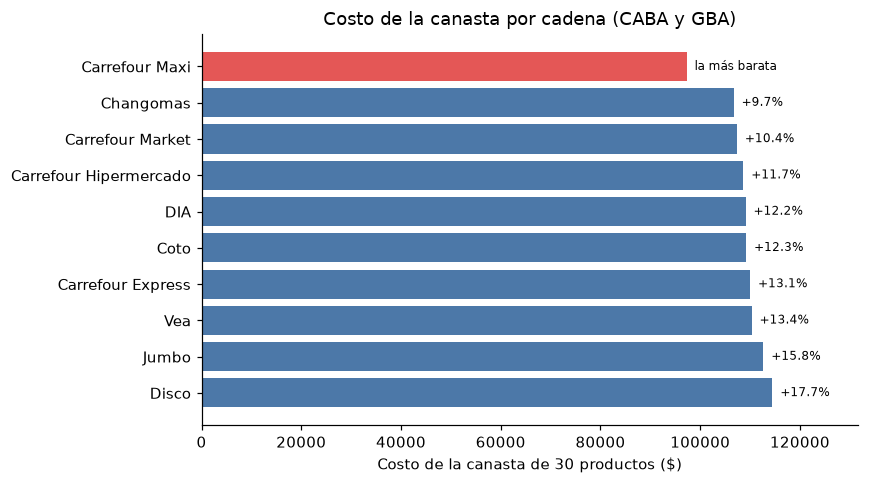

In [4]:
rank = consulta("01_canasta_por_cadena_y_zona.sql")
t = rank[rank["zona"] == "TODAS"].sort_values("costo_canasta", ascending=False)
fig, ax = plt.subplots(figsize=(8, 4.5))
costos = t["costo_canasta"].astype(float)
ax.barh(t["cadena"], costos, color=[RESALTADO if p == 1 else COLOR for p in t["posicion"]])
for y, (c, s) in enumerate(zip(costos, t["sobre_la_mas_barata_pct"])):
    ax.text(c, y, f"  +{s:.1f}%" if s else "  la más barata", va="center", fontsize=8)
ax.set_xlabel("Costo de la canasta de 30 productos ($)")
ax.set_title("Costo de la canasta por cadena (CABA y GBA)")
ax.set_xlim(0, costos.max() * 1.15)
plt.tight_layout()
rank[rank["zona"] == "TODAS"][["posicion", "cadena", "costo_canasta", "sobre_la_mas_barata_pct", "ahorro_vs_mas_cara_pct"]]

**Qué se ve:**
- **Carrefour Maxi es la más barata** y **Disco la más cara**: la misma canasta cuesta un 17,7% más en Disco. Elegir bien la cadena ahorra un 15% sobre el precio de la más cara.
- Carrefour Maxi se despega del resto: la segunda (Changomas) ya está 9,7% arriba. Del segundo al décimo lugar hay 8 puntos de diferencia: un pelotón en el medio y los extremos.
- Jumbo y Disco (Cencosud) son las dos más caras, y Vea queda en el medio.
- Es la canasta de **marcas nacionales** de la decisión 13. No refleja lo que paga quien compra marca propia, que en DIA y en Carrefour es una parte grande de lo que se vende.

## 3. ¿Cuánto más se paga por la marca líder frente a la alternativa?

Prima del producto líder sobre la alternativa **dentro de la misma cadena y el mismo día**. Mediana entre cadenas (al menos 5 cadenas que vendan los dos).

,categoria,prima_mediana_pct,prima_min_pct,prima_max_pct,n_cadenas,dias
0,Detergente lavavajillas 500 ml,36.9,9.5,48.0,9,7
1,Jabón líquido para ropa 800 cc,17.8,16.7,21.4,10,7
2,Crema dental 90 g,12.4,8.8,24.5,10,7
3,Leche entera en sachet 1 L,10.2,-1.0,22.7,10,7
4,Yerba mate 1 kg,8.7,-15.7,16.8,10,7
5,Aceite de girasol 900 cc,-7.3,-16.1,-4.6,10,7


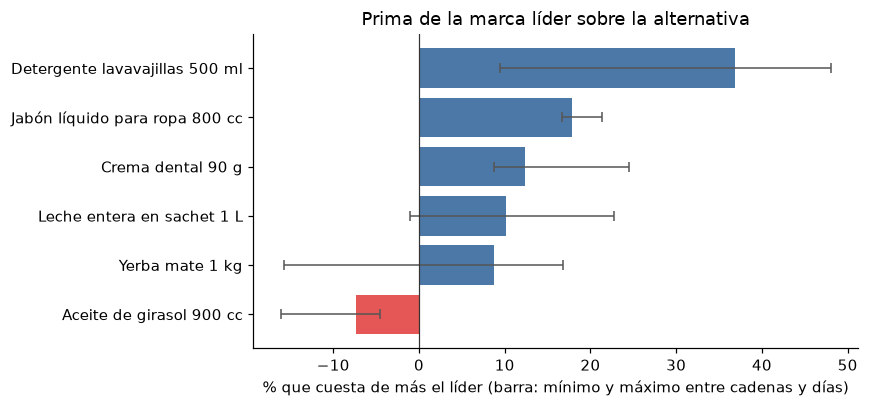

In [5]:
prima = consulta("04_prima_de_marca.sql")
fig, ax = plt.subplots(figsize=(8, 3.8))
d = prima.sort_values("prima_mediana_pct")
ax.barh(d["categoria"], d["prima_mediana_pct"], color=[RESALTADO if v < 0 else COLOR for v in d["prima_mediana_pct"]])
ax.errorbar(d["prima_mediana_pct"], d["categoria"],
            xerr=[d["prima_mediana_pct"] - d["prima_min_pct"], d["prima_max_pct"] - d["prima_mediana_pct"]],
            fmt="none", ecolor="#555", capsize=3, lw=1)
ax.axvline(0, color="#333", lw=0.8)
ax.set_xlabel("% que cuesta de más el líder (barra: mínimo y máximo entre cadenas y días)")
ax.set_title("Prima de la marca líder sobre la alternativa")
plt.tight_layout()
prima

**Qué se ve:**
- La prima va de **−7% a +37%** según la categoría. No hay un número único: depende del producto y del par.
- La líder es más cara en el detergente (+37%), el jabón líquido para ropa (+18%), la crema dental (+12%), la leche (+10%) y la yerba (+9%).
- En el **aceite la prima es negativa** (−7%): Cocinero, el "líder" elegido, cuesta menos que Natura. El "líder" es criterio mío, porque SEPA no informa ventas; no es un error del cálculo.
- Son seis pares y no incluyen marcas propias. Alcanza para mostrar que la prima existe y varía, no para un promedio general de cuánto cuesta la marca.

## 4. ¿Cómo cambian los precios semana a semana y cómo se comparan con el IPC del INDEC?

IPC mensual del INDEC, últimos 12 meses (%):


fecha,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
variacion_mensual_pct,2.5,2.8,2.9,2.9,3.4,2.6,2.1,1.9,2.1,1.7,1.9,2.2


,fecha,zona,n_cadenas,indice
0,2026-11-12,TODAS,7,99.94
1,2026-11-13,TODAS,10,100.00
2,2026-11-14,TODAS,10,100.00
3,2026-11-15,TODAS,10,100.00
4,2026-11-16,TODAS,10,100.00
5,2026-11-17,TODAS,10,100.00
6,2026-11-18,TODAS,10,100.00


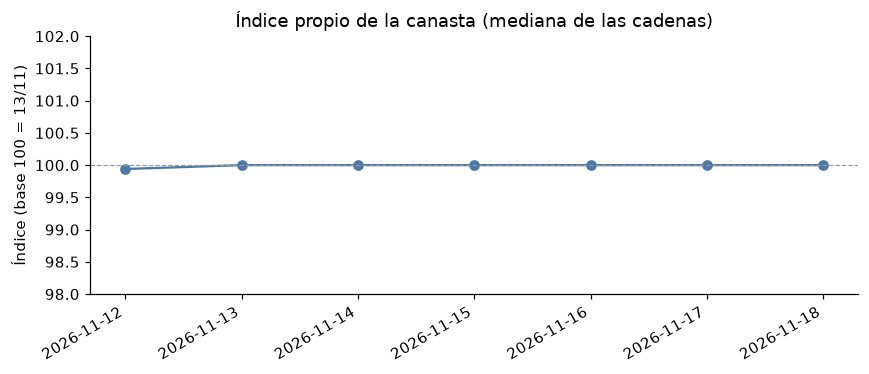

In [6]:
indice = consulta("06_indice_propio.sql")
ipc = pd.read_csv(RAIZ / "data" / "externos" / "ipc.csv", parse_dates=["fecha"]).tail(12)
print("IPC mensual del INDEC, últimos 12 meses (%):")
display(ipc.assign(fecha=ipc["fecha"].dt.strftime("%Y-%m")).set_index("fecha").T)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(indice["fecha"], indice["indice"], marker="o", color=COLOR)
ax.axhline(100, color="#999", lw=0.8, ls="--")
ax.set_ylim(98, 102)
ax.set_ylabel("Índice (base 100 = 13/11)")
ax.set_title("Índice propio de la canasta (mediana de las cadenas)")
fig.autofmt_xdate()
plt.tight_layout()
indice

**Qué se ve y qué no:**
- Del 13 al 18 de noviembre el índice quedó **estable en 100** (el 12/11 vale 99,93): los precios de lista de la canasta no se movieron. La inflación oficial de octubre fue 2,2% mensual, unos 0,07% por día: 0,4% en seis días, que es poco para verlo en una canasta de 30 productos.
- **Todavía no se puede comparar con el IPC.** El IPC es mensual y recién hay una semana. Con 4 o 5 semanas se podrá comparar la variación mensual del índice con el IPC de noviembre, que el INDEC publica a mediados de diciembre.
- Los precios de supermercado suelen actualizarse en saltos (una cadena sube varios productos juntos un día), por eso una semana sin cambios no contradice una inflación mensual de 2%.

## 5. ¿Las promociones son reales o el precio de oferta es el precio de siempre?

Para cada cadena: qué porcentaje de las filas del último día tiene una promoción general (promo1) menor al precio de lista, de cuánto es el descuento, y **cuántos productos que estuvieron en promoción lo estuvieron todos los días en que se los observó** (3 días o más).

,cadena,filas,filas_promo,pct_con_promo,descuento_mediano_pct,pct_promo_permanente
0,DIA,3181494,310432,9.8,21.3,42.8
1,Carrefour Hipermercado,548277,45856,8.4,23.8,57.9
2,Carrefour Market,309131,13900,4.5,20.0,21.2
3,Carrefour Express,1126964,40641,3.6,20.0,15.7
4,Coto,875274,4019,0.5,25.0,18.2


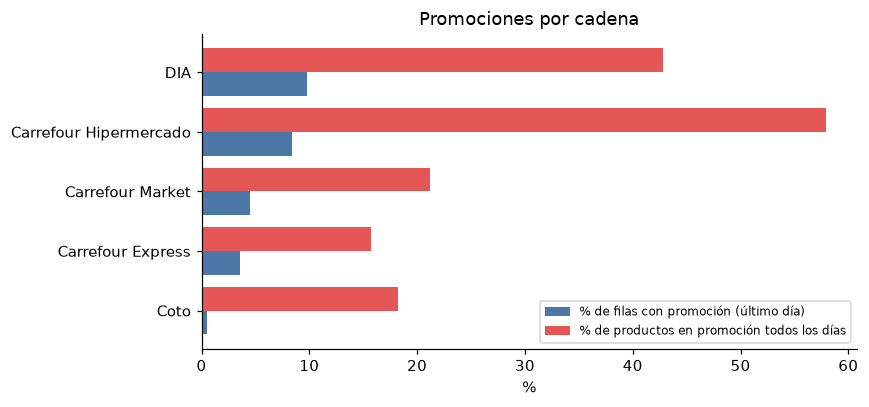

In [7]:
promos = consulta("05_promociones.sql")
fig, ax = plt.subplots(figsize=(8, 3.8))
y = range(len(promos))
ax.barh([i + 0.2 for i in y], promos["pct_con_promo"], height=0.4, label="% de filas con promoción (último día)", color=COLOR)
ax.barh([i - 0.2 for i in y], promos["pct_promo_permanente"], height=0.4, label="% de productos en promoción todos los días", color=RESALTADO)
ax.set_yticks(list(y))
ax.set_yticklabels(promos["cadena"])
ax.invert_yaxis()
ax.legend(fontsize=8, loc="lower right")
ax.set_xlabel("%")
ax.set_title("Promociones por cadena")
plt.tight_layout()
promos

**Qué se ve:**
- Informan promociones DIA, Carrefour (los cuatro formatos), Coto, y en mucha menor medida la Cooperativa Obrera y La Anónima. Las demás cadenas no informan ninguna, así que no se pueden comparar. (La documentación de la etapa 0 decía que solo DIA y la Cooperativa; con más datos eso cambió.)
- En las cadenas que informan, entre 0,5% y 10% de los precios están en promoción, con descuentos medianos de **20% a 25%**: cuando hay promoción, es fuerte.
- **Una parte importante dura toda la ventana:** en Carrefour Hipermercado, el 58% de los productos que estuvieron en promoción lo estuvieron todos los días en que se los observó; en DIA, el 43%. Una oferta que no termina en una semana se parece más a un precio de lista alto con un "descuento" fijo que a una oferta.
- **Límite:** son 7 días. Para decir que la promoción es "el precio de siempre" hay que ver semanas: si la promoción nunca sale, o si la lista sube cuando entra. Esa respuesta necesita más historia.

## Qué falta y por qué las conclusiones son preliminares

- **Historia corta:** 7 días. Las preguntas 4 y 5 necesitan al menos un mes; las comparaciones entre cadenas (1 a 3) ya se leen, pero hay que revisarlas con más días.
- **Marcas nacionales:** la canasta y la prima de marca no incluyen marcas propias.
- **Cadenas:** solo las grandes que informan a SEPA; son precios informados, no de tickets reales ni ventas.
- **Sin ponderar por consumo:** el costo de la canasta suma una unidad de cada producto.